# Analysis — POC small models (ML-mix QLoRA)

How do small code models fine-tuned with QLoRA on the ML code mix (`training/ml-mix/`) compare with the 7B arms of the
thesis? All runs are 0-shot and use the same pipeline (`run_arm.py`), prompts and generation settings.

| Name | Run(s) on the Hub | Model |
|---|---|---|
| `qwen-0.5b-mix` | `qwen-0.5b-mix` | Qwen2.5-Coder-0.5B-Instruct + `dimsmauls/qwen2.5-coder-0.5b-ml-mix-qlora` |
| `deepseek-1.3b-mix` | `deepseek-1.3b-mix` | deepseek-coder-1.3b-instruct + `dimsmauls/deepseek-coder-1.3b-ml-mix-qlora` |
| `vanilla 7B` | `vanilla` | Qwen2.5-Coder-7B-Instruct |
| `lora 7B` | `lora/seed-{42,43,44}` | 7B + LoRA (Code4ML) |
| `qlora 7B` | `qlora/seed-{42,43,44}` | 7B + QLoRA (Code4ML) |
| `qwen-14b` | `qwen-14b` | Qwen2.5-Coder-14B-Instruct |

Same units, seed aggregation and tests as `analysis/index.ipynb`: structural metrics per unique test instruction
(median of duplicate rows, median of seeds), DS-1000 Pass@1 / Pass@10 as binary values per problem (majority of seeds);
McNemar (exact) / Wilcoxon with Holm correction and paired bootstrap CIs. Runs not on the Hub yet are skipped; runs
whose outputs contain raw byte-level BPE tokens (`Ġ` / `Ċ`, a broken tokenizer) are excluded. Structural results need
`code4ml_ratings.csv` (`rating/rate_outputs.ipynb`).

In [1]:
%pip install -q pandas scipy statsmodels huggingface_hub matplotlib   # into the selected kernel (Colab or local)

import os

try:  # Colab secret; elsewhere an existing `hf auth login` is used
    from google.colab import userdata
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
except Exception:
    pass

Note: you may need to restart the kernel to use updated packages.


## 1. Runs and helpers

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import HfApi, hf_hub_download
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

REPO = 'dimsmauls/code4ml-eval-outputs'
SEEDS = (42, 43, 44)
ALPHA = 0.05
BOOTSTRAP = 10_000
SEED = 42
MAX_RAW_TOKEN_SHARE = 0.01   # a run with more completions containing Ġ / Ċ than this is excluded

POC = ['qwen-0.5b-mix', 'deepseek-1.3b-mix']
RUNS = {
    'qwen-0.5b-mix': ['qwen-0.5b-mix'],
    'deepseek-1.3b-mix': ['deepseek-1.3b-mix'],
    'vanilla 7B': ['vanilla'],
    'lora 7B': [f'lora/seed-{s}' for s in SEEDS],
    'qlora 7B': [f'qlora/seed-{s}' for s in SEEDS],
    'qwen-14b': ['qwen-14b'],
}
# each POC model against the 7B baseline and the 7B fine-tuned arm, and the two POC models against each other
PAIRS = [(p, ref) for p in POC for ref in ('vanilla 7B', 'lora 7B')] + [('qwen-0.5b-mix', 'deepseek-1.3b-mix')]

files = set(HfApi().list_repo_files(REPO, repo_type='dataset'))
available = {name: runs for name, runs in RUNS.items() if all(f'{r}/summary.json' in files for r in runs)}
print('on the Hub:', list(available))
print('missing:', sorted(set(RUNS) - set(available)) or 'none')


def get(path):
    return hf_hub_download(REPO, path, repo_type='dataset')


# ---- same helpers as analysis/index.ipynb ----
def holm(pvalues):
    return multipletests(pvalues, method='holm')[1]


def bootstrap_ci(diffs):
    '''Paired bootstrap over units: 95% CI of the mean of per-unit differences.'''
    diffs = np.asarray(diffs, dtype=float)
    rng = np.random.default_rng(SEED)
    means = diffs[rng.integers(0, len(diffs), (BOOTSTRAP, len(diffs)))].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


def wilcoxon_family(table, pairs):
    rows = []
    for a, b in pairs:
        diff = (table[a] - table[b]).dropna()
        nonzero = diff[diff != 0]
        if len(nonzero):
            p = stats.wilcoxon(nonzero).pvalue
            ranks = stats.rankdata(nonzero.abs())
            r = (ranks[nonzero.to_numpy() > 0].sum() - ranks[nonzero.to_numpy() < 0].sum()) / ranks.sum()
        else:
            p, r = 1.0, 0.0
        rows.append({'comparison': f'{a} − {b}', 'n': len(diff), 'median_diff': diff.median(),
                     'mean_diff': diff.mean(), 'p': p, 'rank_biserial': r})
    out = pd.DataFrame(rows)
    out['p_holm'] = holm(out['p'])
    out['significant'] = out['p_holm'] < ALPHA
    return out


def mcnemar_family(table, pairs):
    rows = []
    for a, b in pairs:
        block = table[[a, b]].dropna().astype(int)
        both, only_a = ((block[a] == 1) & (block[b] == 1)).sum(), ((block[a] == 1) & (block[b] == 0)).sum()
        only_b, neither = ((block[a] == 0) & (block[b] == 1)).sum(), ((block[a] == 0) & (block[b] == 0)).sum()
        p = mcnemar([[both, only_a], [only_b, neither]], exact=True).pvalue
        low, high = bootstrap_ci(block[a] - block[b])
        rows.append({'comparison': f'{a} − {b}', 'n': len(block), 'rate_a': block[a].mean(), 'rate_b': block[b].mean(),
                     'diff': block[a].mean() - block[b].mean(), 'ci95_low': low, 'ci95_high': high,
                     'a_only': only_a, 'b_only': only_b, 'p': p})
    out = pd.DataFrame(rows)
    out['p_holm'] = holm(out['p'])
    out['significant'] = out['p_holm'] < ALPHA
    return out


def combine(frames, how):
    '''One value per unit for a cell: median of the seeds, only units present in every seed.'''
    if len(frames) == 1:
        return frames[0]
    stacked = pd.concat(frames, keys=range(len(frames)))
    median = stacked.groupby(level=1).median()
    complete = stacked.groupby(level=1).count() == len(frames)
    return how(median.where(complete))

/Users/dimasmaulana/.venvs/mlx/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


on the Hub: ['qwen-0.5b-mix', 'deepseek-1.3b-mix', 'vanilla 7B', 'lora 7B', 'qlora 7B', 'qwen-14b']
missing: none


## 2. Sanity check: raw tokenizer tokens

In [3]:
# Share of DS-1000 completions with raw byte-level BPE tokens (Ġ = space, Ċ = newline): a tokenizer that does not
# decode them (the first deepseek-1.3b-mix run) gives unreadable code that still parses. Such runs are excluded.
def raw_token_share(run):
    gens = pd.read_json(get(f'{run}/ds1000_generations.jsonl'), lines=True)
    return gens['completion'].str.contains('[ĠĊ]').mean()


raw = {name: raw_token_share(available[name][0]) for name in POC if name in available}
display(pd.Series(raw, name='share with Ġ/Ċ').round(4).to_frame())
broken = [name for name, share in raw.items() if share > MAX_RAW_TOKEN_SHARE]
for name in broken:
    print(f'EXCLUDED {name}: rerun it with the base-model tokenizer (run_arm.py downloads adapter_* only)')
    del available[name]

,share with Ġ/Ċ
qwen-0.5b-mix,0.0000
deepseek-1.3b-mix,0.9966


EXCLUDED deepseek-1.3b-mix: rerun it with the base-model tokenizer (run_arm.py downloads adapter_* only)


## 3. Load ratings and DS-1000 results

In [4]:
GRADE = {g: i for i, g in enumerate('ABCDE', 1)}
STRUCTURAL = ['maintainability', 'code_smells', 'complexity', 'cognitive_complexity', 'bugs', 'mlscent_ml_rating',
              'code_smells_per_100_ncloc', 'has_import']


def has_import(code):
    return float(any(line.lstrip().startswith(('import ', 'from ')) for line in str(code).splitlines()))


def load_ratings(run):
    '''Same as analysis/index.ipynb (SonarQube N/A without ncloc), plus has_import (1 = the answer imports something).'''
    df = pd.read_csv(get(f'{run}/code4ml_ratings.csv'), dtype={'id': str})
    valid = df['ast_valid'].astype(str) == 'True'
    ncloc = pd.to_numeric(df['ncloc'], errors='coerce')
    sonar = valid & (ncloc > 0)
    out = pd.DataFrame(index=df['id'])
    out['ast_valid'] = valid.to_numpy()
    out['ncloc'] = ncloc.where(sonar).to_numpy()
    out['maintainability'] = df['maintainability_rating'].map(GRADE).where(sonar).to_numpy()
    for metric in ('code_smells', 'complexity', 'cognitive_complexity', 'bugs'):
        out[metric] = pd.to_numeric(df[metric], errors='coerce').where(sonar).to_numpy()
    out['mlscent_ml_rating'] = df['mlscent_ml_rating'].map(GRADE).where(valid).to_numpy()
    out['code_smells_per_100_ncloc'] = 100 * out['code_smells'] / out['ncloc']
    out['has_import'] = df['code_block'].map(has_import).where(valid).to_numpy()
    return out


# unit of the structural tests = unique test instruction (304 rows share 40 instruction texts)
INSTRUCTION_OF = pd.read_csv(get('vanilla/code4ml_ratings.csv'), dtype={'id': str}).set_index('id')['graph_vertex_subclass']


def by_instruction(df):
    return df.drop(columns='ast_valid').groupby(INSTRUCTION_OF.reindex(df.index).to_numpy()).median()


def ds1000_binary(run):
    res = pd.read_json(get(f'{run}/ds1000_results.jsonl'), lines=True)
    first = res[res['sample'] == 0].set_index('problem_id')['passed'].astype(float)
    any_pass = res.groupby('problem_id')['passed'].any().astype(float)
    return pd.DataFrame({'pass1': first, 'pass10': any_pass})


rated = {name: runs for name, runs in available.items() if all(f'{r}/code4ml_ratings.csv' in files for r in runs)}
print('not rated yet:', sorted(set(available) - set(rated)) or 'none')
ratings = {r: load_ratings(r) for runs in rated.values() for r in runs}
struct = {name: combine([by_instruction(ratings[r]) for r in runs], lambda df: df) for name, runs in rated.items()}
binary = {name: combine([ds1000_binary(r) for r in runs], lambda df: df.round()) for name, runs in available.items()}
summaries = {r: json.load(open(get(f'{r}/summary.json'))) for runs in available.values() for r in runs}
print('loaded', len(summaries), 'runs')

not rated yet: ['qwen-0.5b-mix']
loaded 9 runs


## 4. Overview: DS-1000 and Code4ML

=== overview (Pass@k: unbiased estimate, mean of seeds)


,pass@1,pass@10,code4ml_ast_valid_rate,generation_minutes,gpu
qwen-0.5b-mix,0.055767,0.184554,0.930921,3.9,NVIDIA GeForce RTX 3080 Ti
vanilla 7B,0.36339,0.661986,0.980263,6.7,NVIDIA GeForce RTX 4090
lora 7B,0.314276,0.613842,0.973684,3.0,NVIDIA GeForce RTX 4090
qlora 7B,0.315914,0.618522,0.976974,2.933333,NVIDIA GeForce RTX 4090
qwen-14b,0.275727,0.541625,1.0,18.8,NVIDIA A100 80GB PCIe



=== DS-1000 pass@1 by library


,qwen-0.5b-mix,vanilla 7B,lora 7B,qlora 7B,qwen-14b
Matplotlib,0.195,0.660,0.534,0.534,0.685
Numpy,0.039,0.376,0.402,0.402,0.182
Pandas,0.022,0.258,0.225,0.227,0.203
Pytorch,0.019,0.349,0.272,0.285,0.144
Scipy,0.034,0.303,0.271,0.273,0.233
Sklearn,0.022,0.283,0.154,0.154,0.192
Tensorflow,0.071,0.333,0.285,0.281,0.311



=== DS-1000 pass@10 by library


,qwen-0.5b-mix,vanilla 7B,lora 7B,qlora 7B,qwen-14b
Matplotlib,0.545,0.877,0.823,0.814,0.890
Numpy,0.145,0.705,0.709,0.714,0.495
Pandas,0.107,0.526,0.510,0.507,0.419
Pytorch,0.103,0.750,0.623,0.652,0.412
Scipy,0.113,0.594,0.519,0.535,0.509
Sklearn,0.104,0.696,0.504,0.539,0.539
Tensorflow,0.133,0.533,0.593,0.548,0.644


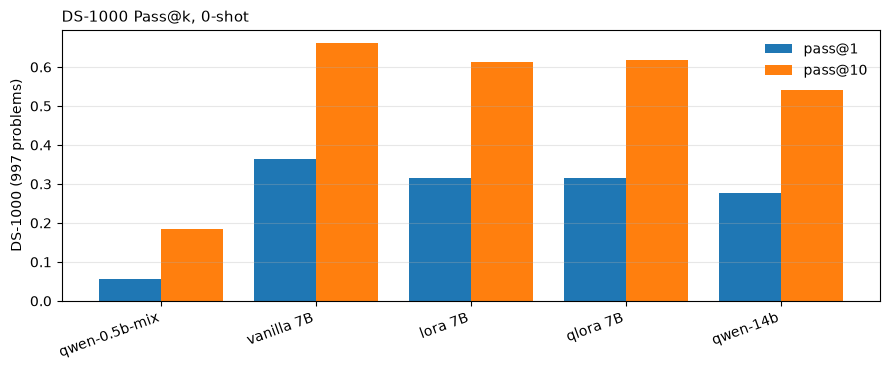

In [5]:
def mean_of(name, value):
    return np.mean([value(summaries[r]) for r in available[name]])


overview = pd.DataFrame({name: {
    'pass@1': mean_of(name, lambda s: s['ds1000']['pass@1']),
    'pass@10': mean_of(name, lambda s: s['ds1000']['pass@10']),
    'code4ml_ast_valid_rate': mean_of(name, lambda s: s['code4ml']['ast_valid_rate']),
    'generation_minutes': mean_of(name, lambda s: s.get('generation_minutes', np.nan)),
    'gpu': summaries[available[name][0]].get('gpu'),
} for name in available}).T
print('=== overview (Pass@k: unbiased estimate, mean of seeds)')
display(overview)

for k in ('pass@1', 'pass@10'):
    by_library = pd.DataFrame({name: pd.Series({lib: v[k] for lib, v in
                                                summaries[available[name][0]]['ds1000'].get('by_library', {}).items()})
                               for name in available if len(available[name]) == 1})
    # seeded arms: mean of the seeds per library
    for name in (n for n in available if len(available[n]) > 1):
        by_library[name] = pd.concat([pd.Series({lib: v[k] for lib, v in summaries[r]['ds1000'].get('by_library', {}).items()})
                                      for r in available[name]], axis=1).mean(axis=1)
    print(f'\n=== DS-1000 {k} by library')
    display(by_library[list(available)].round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(available))
for offset, k in ((-0.2, 'pass@1'), (0.2, 'pass@10')):
    ax.bar(x + offset, overview[k].astype(float), width=0.4, label=k)
ax.set_xticks(x, list(available), rotation=20, ha='right')
ax.set_ylabel('DS-1000 (997 problems)')
ax.set_title('DS-1000 Pass@k, 0-shot', loc='left', fontsize=11)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Structural quality (SonarQube + MLScent)

In [6]:
# Structural quality per model (needs code4ml_ratings.csv): mean over unique instructions, ncloc as median;
# maintainability also as the share of instructions rated A, as reported in the thesis.
def share_a(name):
    rating = struct[name]['maintainability'].dropna()
    return 100 * (rating == 1).mean() if len(rating) else np.nan


if struct:
    table = pd.DataFrame({name: {'instructions_with_ncloc': struct[name]['ncloc'].notna().sum(),
                                 'median_ncloc': struct[name]['ncloc'].median(),
                                 'maintainability_%A': share_a(name),
                                 **{m: struct[name][m].mean() for m in STRUCTURAL}} for name in struct}).T
    display(table.round(3))
else:
    print('no rated run yet: run rating/rate_outputs.ipynb first')

,instructions_with_ncloc,median_ncloc,maintainability_%A,maintainability,code_smells,complexity,cognitive_complexity,bugs,mlscent_ml_rating,code_smells_per_100_ncloc,has_import
vanilla 7B,39.0,13.0,100.000,1.000,0.256,0.205,0.205,0.0,1.588,2.075,0.923
lora 7B,39.0,2.0,97.436,1.026,0.154,0.000,0.000,0.0,1.200,3.022,0.205
qlora 7B,39.0,2.0,97.436,1.026,0.154,0.026,0.026,0.0,1.000,3.083,0.179
qwen-14b,40.0,13.0,100.000,1.000,0.225,0.375,0.375,0.0,1.618,1.693,0.975


## 6. Tests
Each POC model against vanilla 7B and LoRA 7B, and the two POC models against each other: McNemar (exact) on DS-1000 Pass@1 / Pass@10 per problem, Wilcoxon on structural metrics per unique instruction; Holm correction over the pairs of each metric.

In [7]:
pairs = [(a, b) for a, b in PAIRS if a in available and b in available]
print('pairs:', pairs or 'none (runs missing)')
for k in ('pass1', 'pass10') if pairs else []:
    table = pd.DataFrame({name: binary[name][k] for name in available})
    print(f'\n=== DS-1000 {k} (McNemar exact, Holm over the pairs)')
    display(mcnemar_family(table, pairs).round(4))

rated_pairs = [(a, b) for a, b in pairs if a in struct and b in struct]
for metric in STRUCTURAL if rated_pairs else []:
    table = pd.DataFrame({name: struct[name][metric] for name in struct})
    print(f'\n=== {metric} (Wilcoxon, Holm over the pairs; positive diff = higher value for the first model)')
    display(wilcoxon_family(table, rated_pairs).round(4))
if pairs and not rated_pairs:
    print('structural tests: POC runs not rated yet (rating/rate_outputs.ipynb)')

pairs: [('qwen-0.5b-mix', 'vanilla 7B'), ('qwen-0.5b-mix', 'lora 7B')]

=== DS-1000 pass1 (McNemar exact, Holm over the pairs)


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,qwen-0.5b-mix − vanilla 7B,997,0.0502,0.3721,-0.3220,-0.3511,-0.2929,5,326,0.0,0.0,True
1,qwen-0.5b-mix − lora 7B,997,0.0502,0.3089,-0.2588,-0.2869,-0.2307,9,267,0.0,0.0,True



=== DS-1000 pass10 (McNemar exact, Holm over the pairs)


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,qwen-0.5b-mix − vanilla 7B,997,0.1846,0.6620,-0.4774,-0.5095,-0.4463,8,484,0.0,0.0,True
1,qwen-0.5b-mix − lora 7B,997,0.1846,0.6128,-0.4283,-0.4624,-0.3962,16,443,0.0,0.0,True


structural tests: POC runs not rated yet (rating/rate_outputs.ipynb)
